In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El comité de inversión decide el jueves si autoriza la fase de ejecución de un proyecto. Su regla, escrita en el procedimiento, es autorizar sólo si la probabilidad de terminar en el plazo contractual de 22 semanas es al menos del 70%. El cuadro de prelaciones, las duraciones medias y las desviaciones típicas (semanas) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 8       , 1                 ),
    ('B'     , '---'      , 1       , 0.1               ),
    ('C'     , '---'      , 8       , 1                 ),
    ('D'     , 'A'        , 2       , 0.3               ),
    ('E'     , 'B'        , 1       , 0.6               ),
    ('F'     , 'B,C,D'    , 5       , 0.6               ),
    ('G'     , 'D,E'      , 5       , 1                 ),
    ('H'     , 'F,G'      , 5       , 1                 ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,8,1.0
B,---,1,0.1
C,---,8,1.0
D,A,2,0.3
E,B,1,0.6
F,"B,C,D",5,0.6
G,"D,E",5,1.0
H,"F,G",5,1.0


El lunes el jefe de proyecto recibe una llamada: el único proveedor cualificado de la actividad G ha entrado en concurso de acreedores. Su estimación, contrastada con compras, es que con probabilidad 50% habrá que cambiar de proveedor, lo que añadiría 3 semanas a G.

> **De: Jefe de proyecto (al responsable de riesgos)**
> El informe para el comité está cerrado desde el viernes con la probabilidad que calculamos; no voy a reabrirlo por una llamada. Si el proveedor cae, lo gestionamos como riesgo en ejecución. No lo menciones el jueves.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C4 — Retención de información.** Callar un hecho conocido que la otra parte necesitaría para decidir (un riesgo, una holgura, una discrepancia). *(cf. Código Ético del PMI, 5.3.1 y 5.2.3.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la probabilidad de terminar en 22 semanas o menos sin el riesgo, con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales).  "
pregunta_2 = "2. (A) Incorpore el riesgo a la simulación (la duración de G es normal más 3 semanas con probabilidad 50%) y recalcule la probabilidad. ¿Cambia la decisión del comité según su regla?  "
pregunta_3 = "3. (B) ¿Qué criterio de referencia incumple no mencionar el riesgo el jueves? ¿Es relevante que el riesgo pueda «gestionarse en ejecución»? ¿Qué convierte a la omisión en material?  "
pregunta_4 = "4. (C) ¿Qué hace el responsable de riesgos antes del jueves y qué dice al jefe de proyecto y al comité? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la probabilidad de terminar en 22 semanas o menos sin el riesgo, con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales).  

2. (A) Incorpore el riesgo a la simulación (la duración de G es normal más 3 semanas con probabilidad 50%) y recalcule la probabilidad. ¿Cambia la decisión del comité según su regla?  

3. (B) ¿Qué criterio de referencia incumple no mencionar el riesgo el jueves? ¿Es relevante que el riesgo pueda «gestionarse en ejecución»? ¿Qué convierte a la omisión en material?  

4. (C) ¿Qué hace el responsable de riesgos antes del jueves y qué dice al jefe de proyecto y al comité? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
plazo, umbral, X, p_riesgo, delta = 22, 0.7, 'G', 0.5, 3
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
p_pert = float(norm.cdf((plazo - duracion) / sigma))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = 0+8 = 8$ &nbsp; (A)
- $T_{E} = 0+1 = 1$ &nbsp; (B)
- $T_{F} = \max\{0+1,\ 0+8,\ 8+2\} = 10$ &nbsp; (B, C, D)
- $T_{G} = \max\{8+2,\ 1+1\} = 10$ &nbsp; (D, E)
- $T_{H} = \max\{10+5,\ 10+5\} = 15$ &nbsp; (F, G)
- $T_{\mathrm{Fin}} = 15+5 = 20$ &nbsp; (H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 20$
- $T_{H}^{*} = 20-5 = 15$ &nbsp; (Fin)
- $T_{G}^{*} = 15-5 = 10$ &nbsp; (H)
- $T_{F}^{*} = 15-5 = 10$ &nbsp; (H)
- $T_{E}^{*} = 10-1 = 9$ &nbsp; (G)
- $T_{D}^{*} = \min\{10-2,\ 10-2\} = 8$ &nbsp; (F, G)
- $T_{C}^{*} = 10-8 = 2$ &nbsp; (F)
- $T_{B}^{*} = \min\{9-1,\ 10-1\} = 8$ &nbsp; (E, F)
- $T_{A}^{*} = 8-8 = 0$ &nbsp; (D)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 8-0,\ 2-0\} = 0$ &nbsp; (A, B, C)

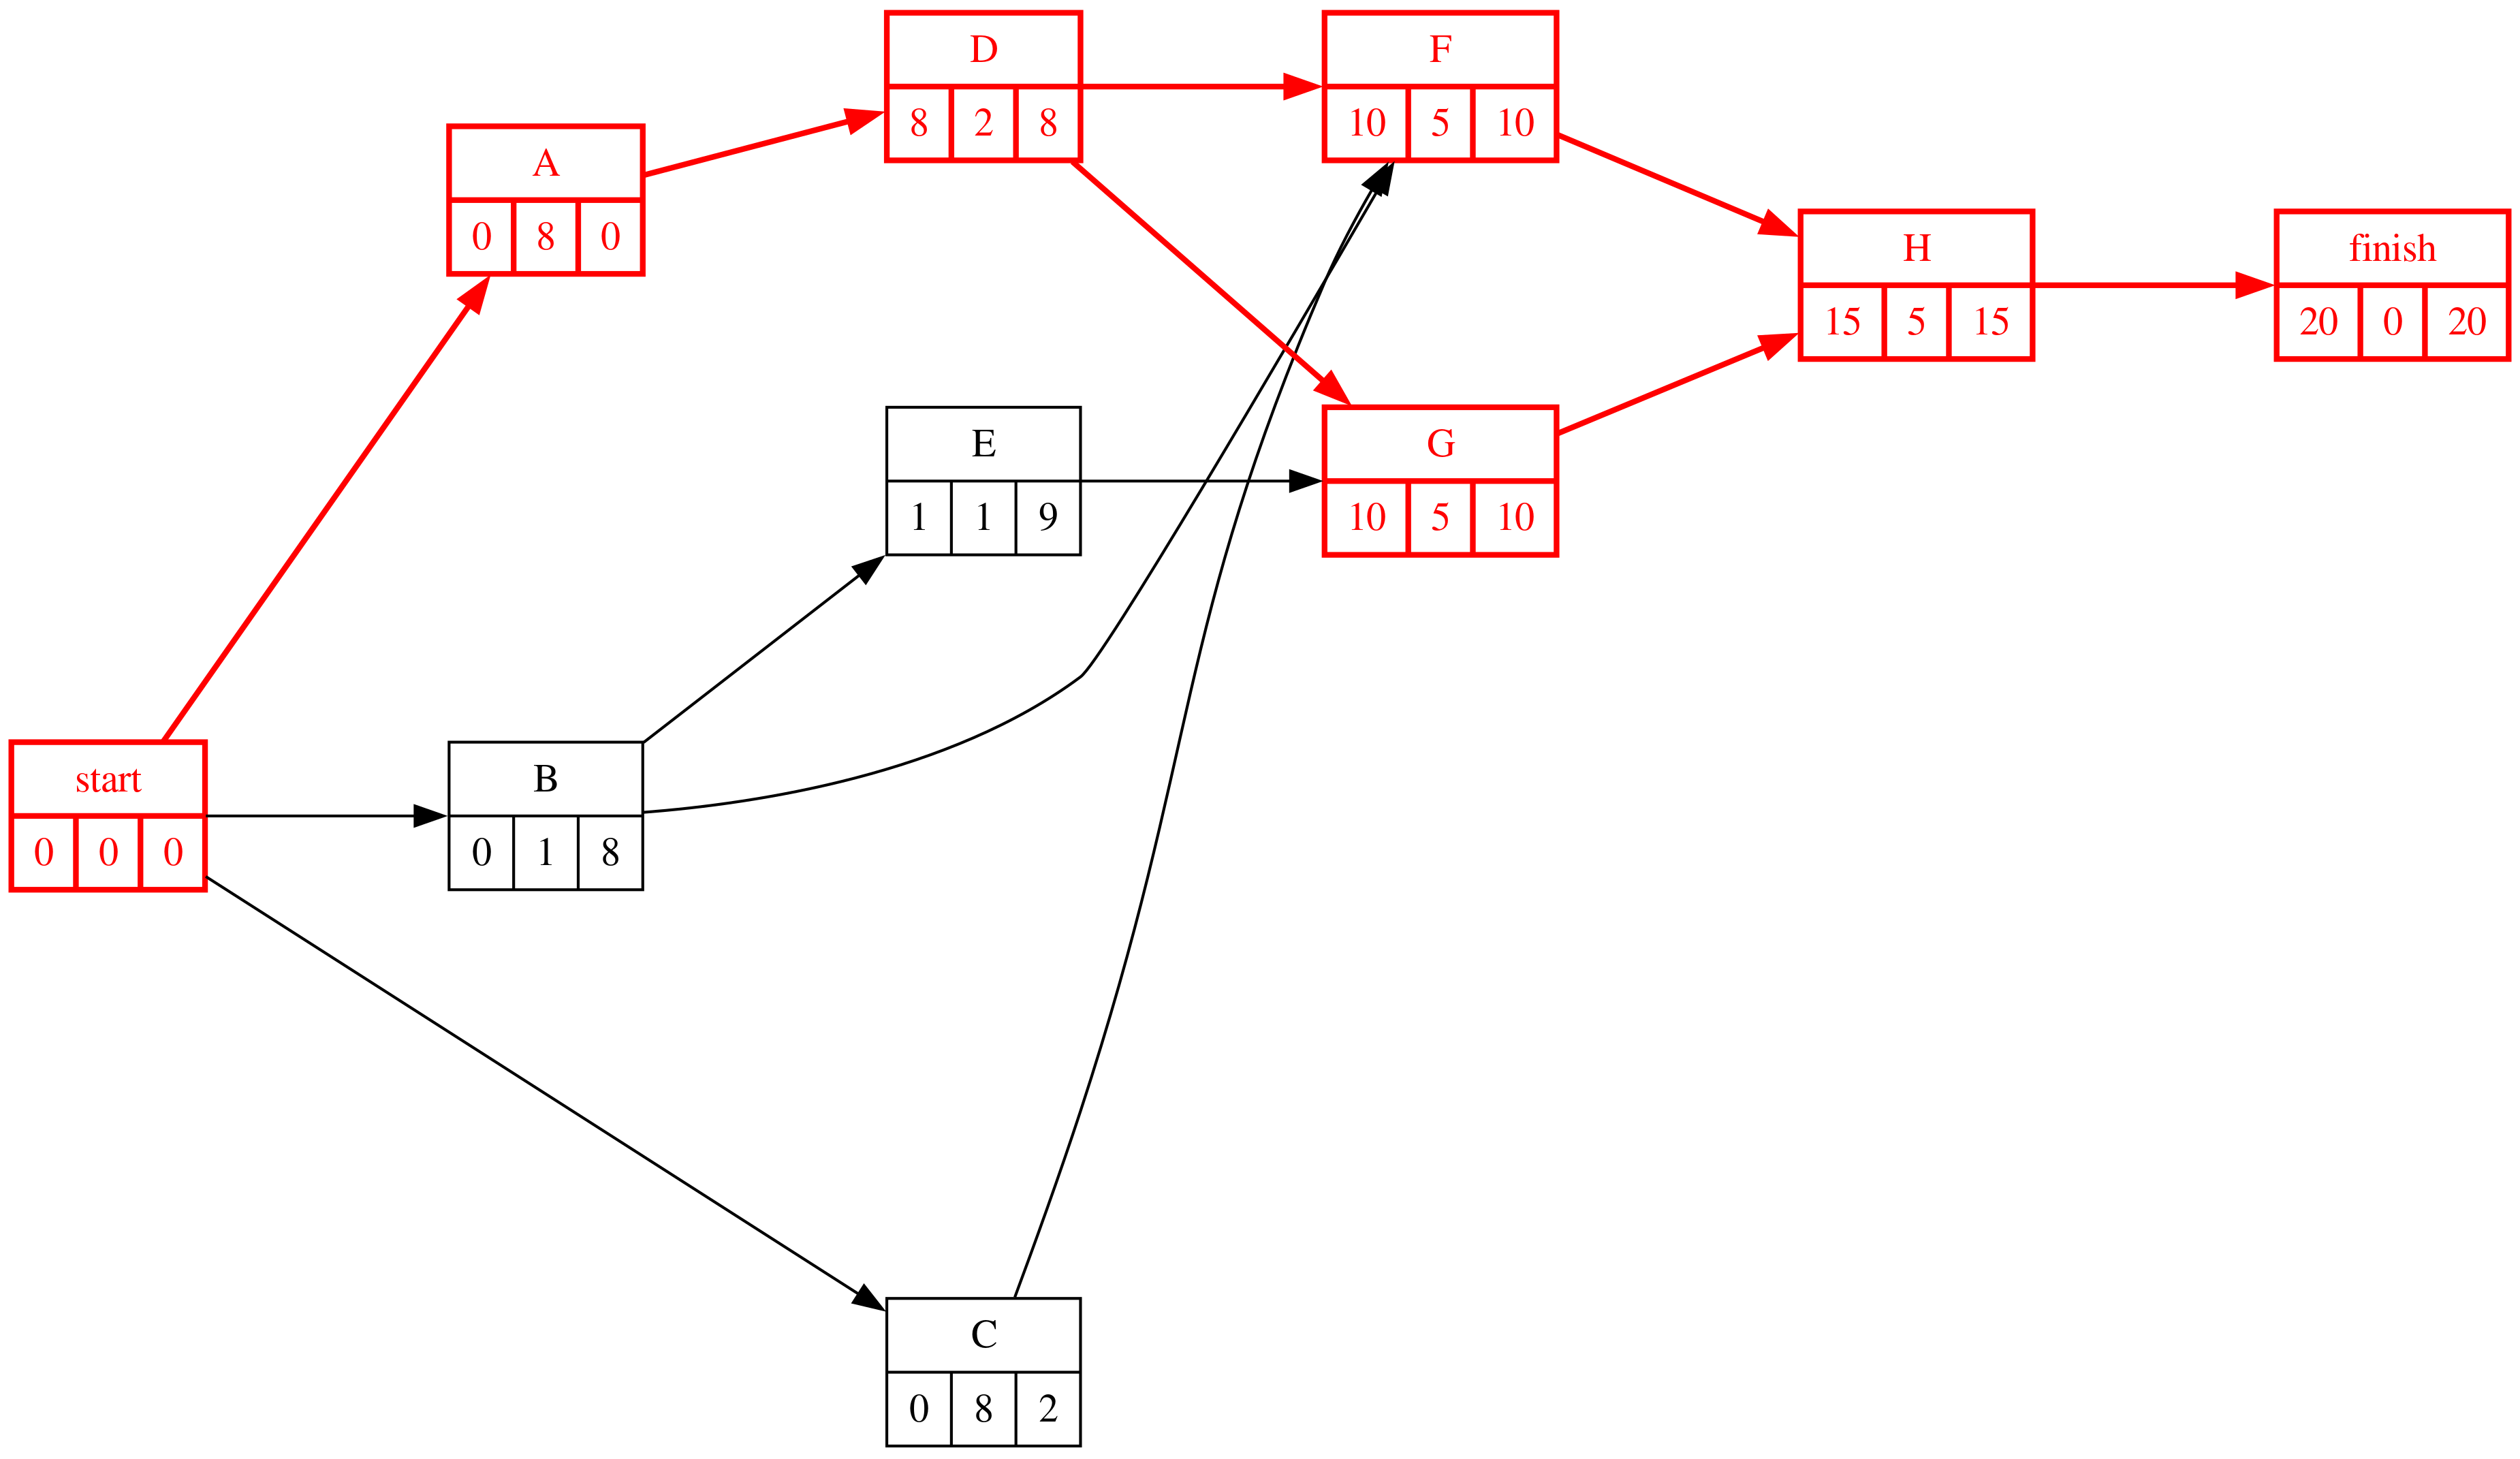

In [8]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la probabilidad de terminar en 22 semanas o menos sin el riesgo, con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales).  

In [10]:
#| tbl-cap: "Duración y varianza de cada ruta"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
display(detalle_rutas(R, datos_proyecto['duration'], 'duración'))
detalle_rutas(R, datos_proyecto['variance'], 'varianza', 3)

,actividades,duración = suma,duración
Route_1,A - D - F - H,A(8) + D(2) + F(5) + H(5) = 20,20.0
Route_2,A - D - G - H,A(8) + D(2) + G(5) + H(5) = 20,20.0
Route_3,B - E - G - H,B(1) + E(1) + G(5) + H(5) = 12,12.0
Route_4,B - F - H,B(1) + F(5) + H(5) = 11,11.0
Route_5,C - F - H,C(8) + F(5) + H(5) = 18,18.0


,actividades,varianza = suma,varianza
Route_1,A - D - F - H,A(1.000) + D(0.090) + F(0.360) + H(1.000) = 2.450,2.45
Route_2,A - D - G - H,A(1.000) + D(0.090) + G(1.000) + H(1.000) = 3.090,3.09
Route_3,B - E - G - H,B(0.010) + E(0.360) + G(1.000) + H(1.000) = 2.370,2.37
Route_4,B - F - H,B(0.010) + F(0.360) + H(1.000) = 1.370,1.37
Route_5,C - F - H,C(1.000) + F(0.360) + H(1.000) = 2.360,2.36


In [11]:
dists = {act: ('normal', fila['duration'], fila['standard_deviation']) for act, fila in datos_proyecto.iterrows()}
sin_riesgo = proyecto.monte_carlo(dict(dists), n_samples=20000, seed=2024)
p_mc0 = float((np.asarray(sin_riesgo.tau_samples) <= plazo).mean())
Markdown(f'''Sin el riesgo: duración esperada {duracion}, σ = {sigma:.2f}, **P(T ≤ {plazo}) = {p_pert:.2f}** (PERT) y **{p_mc0:.2f}** (Monte Carlo). Supera el umbral del {umbral:.0%}: el comité autorizaría.''')

Sin el riesgo: duración esperada 20, σ = 1.76, **P(T ≤ 22) = 0.87** (PERT) y **0.83** (Monte Carlo). Supera el umbral del 70%: el comité autorizaría.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. (A) Incorpore el riesgo a la simulación (la duración de G es normal más 3 semanas con probabilidad 50%) y recalcule la probabilidad. ¿Cambia la decisión del comité según su regla?  

In [13]:
rng_mc = np.random.default_rng(2024)
mu_X, sd_X = float(datos_proyecto.loc[X, 'duration']), float(datos_proyecto.loc[X, 'standard_deviation'])
def duracion_X_con_riesgo(size=None):
    '''Normal más delta semanas con probabilidad p_riesgo (cambio de proveedor).'''
    return rng_mc.normal(mu_X, sd_X, size) + delta * (rng_mc.random(size) < p_riesgo)
dists_riesgo = dict(dists); dists_riesgo[X] = duracion_X_con_riesgo
con_riesgo = proyecto.monte_carlo(dists_riesgo, n_samples=20000, seed=2024)
p_mc1 = float((np.asarray(con_riesgo.tau_samples) <= plazo).mean())
comparacion = pd.DataFrame({'sin el riesgo': sin_riesgo.summary().iloc[:, 0], 'con el riesgo': con_riesgo.summary().iloc[:, 0]})
display(comparacion.round(2))
Markdown(f'''Con el riesgo: **P(T ≤ {plazo}) = {p_mc1:.2f}**, por debajo del umbral del {umbral:.0%}. La decisión del comité cambia: con la información del lunes no autorizaría (o exigiría un plan de mitigación antes).''')

,sin el riesgo,con el riesgo
τ,20.5,21.76


Con el riesgo: **P(T ≤ 22) = 0.56**, por debajo del umbral del 70%. La decisión del comité cambia: con la información del lunes no autorizaría (o exigiría un plan de mitigación antes).

Comprobación a mano: G es crítica, así que las 3 semanas van enteras al plazo cuando el riesgo se materializa; la probabilidad es aproximadamente 50% · P(T ≤ 22) + 50% · P(T ≤ 19) = 0.58 con el PERT, en línea con la simulación.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) ¿Qué criterio de referencia incumple no mencionar el riesgo el jueves? ¿Es relevante que el riesgo pueda «gestionarse en ejecución»? ¿Qué convierte a la omisión en material?  

**C4 (retención de información).** El comité decide con una regla explícita sobre una cifra, y el jefe de proyecto sabe un hecho que la mueve de 0.83 a 0.56, de un lado al otro del umbral. Que el riesgo pueda gestionarse en ejecución no cambia nada: la decisión de autorizar es del comité, y se le estaría quitando la posibilidad de tomarla con los datos. La omisión es **material** precisamente porque la decisión cambia con el dato; ese es el test objetivo (si el riesgo dejara la probabilidad por encima del umbral, seguiría siendo obligatorio informar —5.2.3— pero no cambiaría la decisión).

In [15]:
preguntas_test = [
    ('No comunicar al comité un riesgo conocido que cambia su decisión es…', ['C4, retención de información', 'C2, verdad a medias', 'C8, reserva declarada', 'gestión de riesgos en ejecución'],
     'Se calla un hecho conocido que la otra parte necesita para decidir.'),
    ('La omisión es material cuando…', ['la decisión cambia con el dato omitido', 'el riesgo tiene probabilidad mayor que 0,5', 'el informe ya está cerrado', 'el dato llega por teléfono'],
     'El test objetivo es si la cifra que gobierna la decisión cruza el umbral.'),
    ('Si G no fuera crítica, el efecto del riesgo en el plazo sería…', ['menor, absorbido en parte por su holgura', 'el mismo', 'mayor', 'nulo siempre'],
     'Un retraso x en una actividad con holgura H retrasa el proyecto máx(0, x − H).'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — riesgo silenciado')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — riesgo silenciado

::Ética 19 — riesgo silenciado P1::No comunicar al comité un riesgo conocido que cambia su decisión es… {=C4, retención de información ~C2, verdad a medias ~C8, reserva declarada ~gestión de riesgos en ejecución ####Se calla un hecho conocido que la otra parte necesita para decidir.}

::Ética 19 — riesgo silenciado P2::La omisión es material cuando… {~el dato llega por teléfono =la decisión cambia con el dato omitido ~el informe ya está cerrado ~el riesgo tiene probabilidad mayor que 0,5 ####El test objetivo es si la cifra que gobierna la decisión cruza el umbral.}

::Ética 19 — riesgo silenciado P3::Si G no fuera crítica, el efecto del riesgo en el plazo sería… {~nulo siempre =menor, absorbido en parte por su holgura ~el mismo ~mayor ####Un retraso x en una actividad con holgura H retrasa el proyecto máx(0, x − H).}



## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué hace el responsable de riesgos antes del jueves y qué dice al jefe de proyecto y al comité? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Antes del jueves: recalcular (dos horas de trabajo), redactar una página con las dos probabilidades y un plan de mitigación (proveedor alternativo precalificado, acopio anticipado, acortar otra actividad crítica) con su coste, y llevarla al jefe de proyecto. Al jefe de proyecto: «el informe tiene una cifra que sabemos que ya no es cierta; si el comité lo descubre después, el problema no es el proveedor sino nosotros». Al comité, con o sin el acuerdo del jefe de proyecto: la actualización y el plan; el criterio 2.3.2 del Código del PMI pide elevar la cuestión a quien corresponde cuando no se resuelve en el nivel propio. Lo que no cabe: callar el jueves y «gestionarlo en ejecución».